# Conditional Flow Matching with Image-Domain Embeddings

In [1]:
import time

import torch 
from torch import nn, Tensor
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import numpy as np

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

### Load MNIST dataset

In [3]:


# Normalize pixel values from [0, 1] to [-1, 1] so the data matches a standard
# Gaussian source for flow matching.
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = datasets.MNIST(root='../data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='../data', train=False, download=True, transform=transform)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f'Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}')
images, labels = next(iter(train_loader))
print(f'Batch images shape: {images.shape}, labels shape: {labels.shape}')

Train samples: 60000, Test samples: 10000
Batch images shape: torch.Size([128, 1, 28, 28]), labels shape: torch.Size([128])


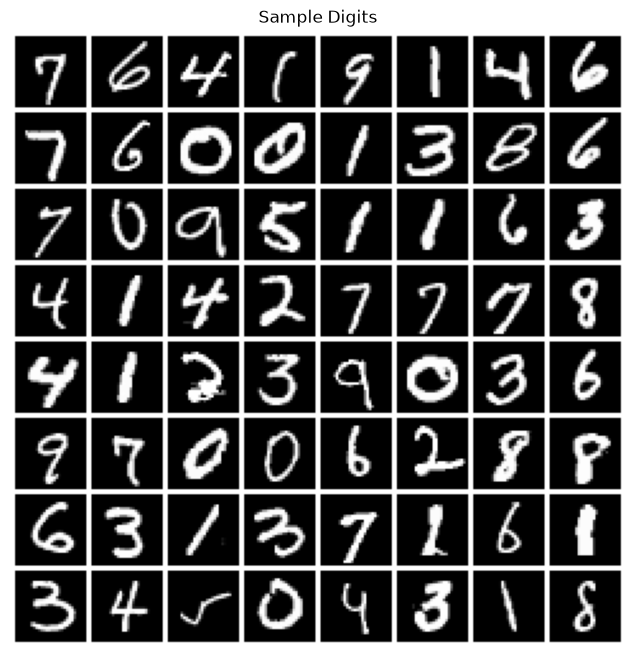

In [4]:
## Display some sample digits

def show_samples(images: Tensor, nrow: int=8, ax=None):
    # images = (images + 1) / 2  # denormalize
    images = images.clamp(0, 1)
    grid = make_grid(images[:nrow**2], nrow, padding=2, pad_value=1)
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    ax.set_aspect('equal')
    ax.set_title('Sample Digits')
    ax.imshow(grid.permute(1, 2, 0).cpu())
    ax.axis('off')
    return ax

show_samples(images);

In [5]:
def train_cond(flow, train_loader, n_epochs=50, lr=1e-3, sigma_noise=0.1, device=device):
    losses = []
    opt = torch.optim.Adam(flow.parameters(), lr=lr)
    for e in range(n_epochs):
        current_loss = 0.0
        for i, (x, c) in enumerate(train_loader):
            x_1 = x.view(-1, 784).to(device)
            c = c.to(device)

            t = torch.rand(x.shape[0], 1, device=x_1.device)
            x_0 = torch.randn_like(x_1)*sigma_noise + 0.5
            dx_t = x_1 - x_0
            x_t = (1-t)*x_0 + t * x_1
            flow_pred = flow(t=t, c=c, x_t=x_t)

            loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
            loss.backward()
            opt.step()
            opt.zero_grad()

            current_loss += loss.item()
        avg_loss = current_loss / len(train_loader)
        losses.append(avg_loss)

    return losses

### Learning conditional embeddings in the image domain

In [6]:
class CondFlow(nn.Module):
    def __init__(self, dim: int = 784, h: int = 64):
        super().__init__()
        self.class_emb = nn.Embedding(10, dim)
        self.encoder = nn.Sequential(
            nn.Linear(dim+1, h),
            nn.ReLU(),
            nn.Linear(h, h),
        )
        self.decoder = nn.Sequential(
            nn.Linear(h, h),
            nn.ReLU(),
            nn.Linear(h, dim),
            # nn.Sigmoid()
        )
    
    def forward(self, t: Tensor, c: Tensor, x_t: Tensor ) -> Tensor:
        c_emb = self.class_emb(c)
        inp = torch.cat((x_t + c_emb, t), 1)
        z = self.encoder(inp)
        return self.decoder(z)
    
    def step(self, x_t: Tensor, t_start: Tensor, t_end: Tensor, c: Tensor) -> Tensor:
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t + dt * self(x_t=x_t + self(x_t=x_t, t=t_start, c=c)*dt/2, t=t_start + dt/2, c=c)

In [15]:
cond_flow = CondFlow(h=256).to(device)
losses = train_cond(cond_flow, train_loader, n_epochs=200, lr=1e-3, sigma_noise=0.03, device=device)

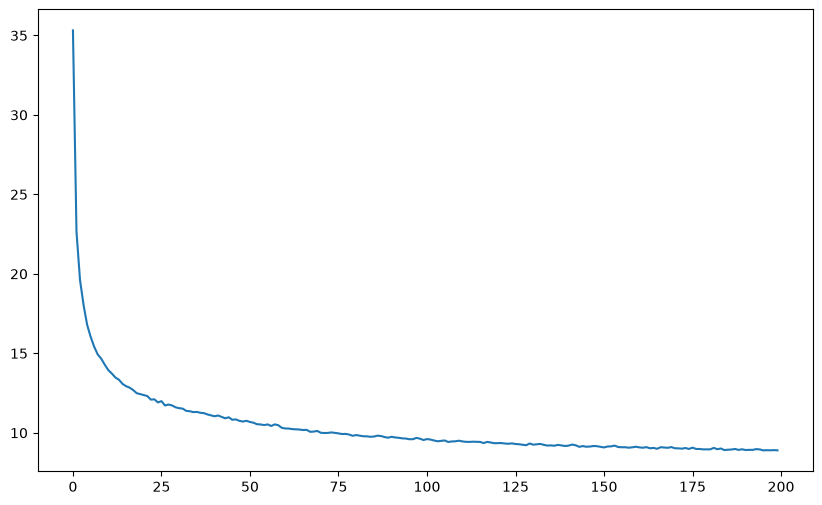

In [16]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(losses)
plt.show();

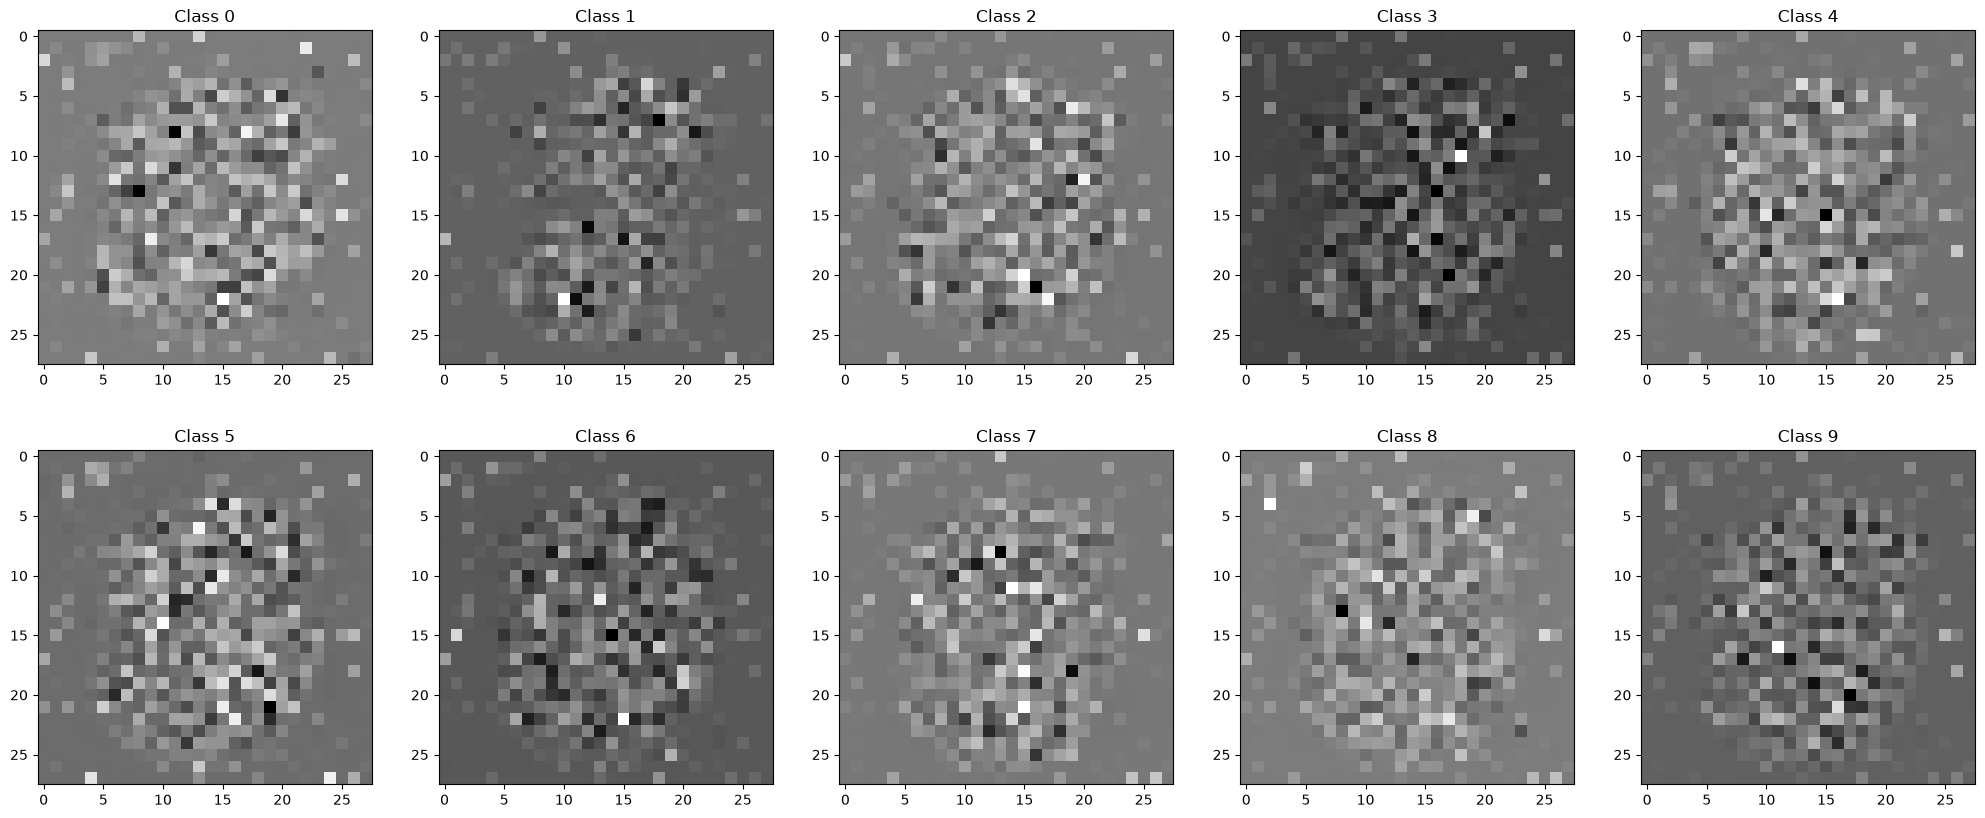

In [17]:
fig, ax = plt.subplots(2, 5, figsize=(25, 10))
ax = ax.reshape(-1)
for i in range(10):
    mu = cond_flow.class_emb(torch.tensor(i).to(device)).detach().cpu()
    # mu_scaled = (mu - mu.min()) / (mu.max() - mu.min())
    ax[i].imshow(mu.view(28, 28), cmap='gray')
    ax[i].set_title(f'Class {i}')

plt.show()

In [18]:
mu

tensor([-4.6383e-01, -4.6379e-01, -4.6284e-01, -4.6496e-01, -4.5889e-01,
        -4.6270e-01, -4.6221e-01, -4.6681e-01, -9.6411e-02, -4.6375e-01,
        -4.5934e-01, -4.6368e-01, -4.6471e-01,  3.6155e-01, -4.6378e-01,
        -4.6041e-01, -4.6142e-01, -4.0921e-01, -4.6474e-01, -4.6455e-01,
        -4.6328e-01, -4.6183e-01, -4.5955e-01, -4.6521e-01, -4.6343e-01,
        -4.5230e-01, -4.6269e-01, -4.5968e-01, -4.5296e-01, -1.2974e-01,
        -4.6518e-01, -4.5843e-01, -8.7959e-02, -1.9615e-01, -4.5717e-01,
        -1.7759e-01, -4.6302e-01, -4.5744e-01, -1.0623e-01, -4.6044e-01,
        -4.6160e-01, -4.6275e-01, -4.5944e-01, -4.6524e-01, -4.6207e-01,
        -4.6570e-01, -4.6337e-01, -4.5604e-01, -4.6214e-01, -4.5906e-01,
         2.1642e-01, -4.5917e-01, -4.6645e-01, -4.6321e-01, -4.6331e-01,
        -4.5651e-01,  6.6002e-02, -4.5431e-01, -3.4160e-01, -4.6397e-01,
        -1.5465e-01,  5.7289e-02, -4.6120e-01, -4.6663e-01, -4.6342e-01,
        -4.5986e-01, -4.6252e-01, -4.6013e-01, -4.6